# Single-track train delay propagation

How much waiting does a late train cause at a zero-buffer crossing? The synthetic timetable represents Peradeniya Junction, Gampola and Nawalapitiya. Historical scheduled journey times are used as fixed segment durations.

In [1]:
import csv
from collections import defaultdict, deque
from heapq import heappop, heappush
from io import StringIO
from pathlib import Path

# Embedded copy lets this small example run in a fresh Colab session.
embedded_csv = """train,origin,destination,departure,arrival
A,Peradeniya Junction,Gampola,09:39,10:00
A,Gampola,Nawalapitiya,10:02,10:27
B,Nawalapitiya,Gampola,09:31,09:58
B,Gampola,Peradeniya Junction,10:00,10:18
C,Peradeniya Junction,Gampola,10:18,10:39
C,Gampola,Nawalapitiya,10:41,11:06
"""
paths = [Path("data/baseline_timetable.csv"), Path("../data/baseline_timetable.csv")]
source = next((path for path in paths if path.is_file()), None)
rows = list(csv.DictReader(StringIO(source.read_text() if source else embedded_csv)))

def minute(clock):
    hour, minutes = map(int, clock.split(":"))
    return 60 * hour + minutes

def clock(minutes):
    return f"{minutes // 60:02d}:{minutes % 60:02d}"

for row in rows:
    row["start"] = minute(row["departure"])
    row["duration"] = minute(row["arrival"]) - row["start"]
    row["segment"] = tuple(sorted((row["origin"], row["destination"])))

## Movement rules

Each segment admits one train at a time in scheduled departure order. A train can depart once its timetable permits, its entry delay or two-minute station dwell has elapsed, and the segment is free. The clock jumps to the next readiness or arrival event. All arrivals at the same minute release their segments before departures. For this three-service plan the fixed segment orders allow at most two trains at Gampola.

In [2]:
def simulate(entry_delays, timetable=None):
    if timetable is None:
        timetable = rows
    orders = defaultdict(deque)
    routes = defaultdict(list)
    for i in sorted(range(len(timetable)), key=lambda i: timetable[i]["start"]):
        orders[timetable[i]["segment"]].append(i)
        routes[timetable[i]["train"]].append(i)

    events = []
    next_leg = {}
    for train, legs in routes.items():
        first = legs[0]
        heappush(events, (timetable[first]["start"] + entry_delays.get(train, 0), "ready", first))
        next_leg.update(zip(legs, legs[1:]))

    occupied = set()
    ready_since = {}
    movements = {}
    while events:
        now = events[0][0]
        while events and events[0][0] == now:
            _, event, i = heappop(events)
            if event == "ready":
                ready_since[i] = now
            else:
                occupied.remove(timetable[i]["segment"])
                if i in next_leg:
                    j = next_leg[i]
                    heappush(events, (max(now + 2, timetable[j]["start"]), "ready", j))

        for segment, order in orders.items():
            if segment in occupied or not order or order[0] not in ready_since:
                continue
            i = order.popleft()
            arrival = now + timetable[i]["duration"]
            movements[i] = (now, arrival, now - ready_since.pop(i))
            occupied.add(segment)
            heappush(events, (arrival, "arrive", i))

    assert len(movements) == len(timetable), "Some trains could not finish"
    return movements

## Check against the hand calculation

The third value recorded for each movement is the time spent waiting after the train was ready and its timetable permitted departure. An imposed entry delay is counted separately.

In [3]:
baseline = simulate({})
disrupted = simulate({"A": 25})
for i, row in enumerate(rows):
    assert baseline[i] == (row["start"], minute(row["arrival"]), 0)
    depart, arrive, wait = disrupted[i]
    print(f"{row['train']}  {row['origin']} to {row['destination']}: "
          f"{clock(depart)} to {clock(arrive)}, conflict wait {wait} min")

other_wait = sum(disrupted[i][2] for i, row in enumerate(rows) if row["train"] != "A")
assert other_wait == 50
for train, origin, expected in [("B", "Gampola", "10:25"), ("C", "Peradeniya Junction", "10:43")]:
    i = next(i for i, r in enumerate(rows) if (r["train"], r["origin"]) == (train, origin))
    assert disrupted[i][0] == minute(expected) and disrupted[i][2] == 25
print(f"Additional waiting across B and C: {other_wait} train-minutes.")

A  Peradeniya Junction to Gampola: 10:04 to 10:25, conflict wait 0 min
A  Gampola to Nawalapitiya: 10:27 to 10:52, conflict wait 0 min
B  Nawalapitiya to Gampola: 09:31 to 09:58, conflict wait 0 min
B  Gampola to Peradeniya Junction: 10:25 to 10:43, conflict wait 25 min
C  Peradeniya Junction to Gampola: 10:43 to 11:04, conflict wait 25 min
C  Gampola to Nawalapitiya: 11:06 to 11:31, conflict wait 0 min
Additional waiting across B and C: 50 train-minutes.


## Five-minute crossing buffer at Gampola

Schedule B to leave Gampola five minutes later and shift both legs of C by five minutes so C can use the segment after B. B's scheduled journey increases by five minutes. C starts and finishes five minutes later with the same scheduled journey duration. Compare on-time and disrupted runs against this revised timetable.

In [4]:
def crossing_timetable(buffer_minutes):
    timetable = []
    for original in rows:
        leg = original.copy()
        if leg["train"] == "C" or (leg["train"] == "B" and leg["origin"] == "Gampola"):
            leg["start"] += buffer_minutes
            leg["departure"] = clock(leg["start"])
            leg["arrival"] = clock(leg["start"] + leg["duration"])
        timetable.append(leg)
    return timetable

buffered = crossing_timetable(5)
on_time = simulate({}, buffered)
late = simulate({"A": 25}, buffered)
for i, leg in enumerate(buffered):
    assert on_time[i] == (leg["start"], minute(leg["arrival"]), 0)

for train, station, scheduled, actual in [
    ("B", "Gampola", "10:05", "10:25"),
    ("C", "Peradeniya Junction", "10:23", "10:43"),
]:
    i = next(i for i, leg in enumerate(buffered)
             if leg["train"] == train and leg["origin"] == station)
    assert on_time[i][0] == minute(scheduled)
    assert late[i][0] == minute(actual) and late[i][2] == 20
    print(f"{train} at {station}: scheduled {scheduled}, departed {actual}, extra wait {late[i][2]} min")

extra_wait = sum(late[i][2] - on_time[i][2] for i, leg in enumerate(buffered) if leg["train"] != "A")
assert extra_wait == 40
print(f"Additional waiting across B and C: {extra_wait} train-minutes")

B at Gampola: scheduled 10:05, departed 10:25, extra wait 20 min
C at Peradeniya Junction: scheduled 10:23, departed 10:43, extra wait 20 min
Additional waiting across B and C: 40 train-minutes


## Compare four crossing buffers

Only A enters late, by 25 minutes. For each buffer, compare a disrupted run with an on-time run on the same timetable. Report the extra conflict waiting for B and C in train-minutes. The timetable cost is the increase in minutes from the first scheduled departure to the last scheduled arrival.

In [5]:
base_span = max(minute(r["arrival"]) for r in rows) - min(r["start"] for r in rows)
print("Buffer (min) | B wait | C wait | Total (train-min) | Added timetable span (min)")
for buffer in (0, 5, 10, 15):
    schedule = crossing_timetable(buffer)
    normal = simulate({}, schedule)
    disrupted_run = simulate({"A": 25}, schedule)
    waits = defaultdict(int)
    for i, leg in enumerate(schedule):
        assert normal[i] == (leg["start"], minute(leg["arrival"]), 0)
        waits[leg["train"]] += disrupted_run[i][2] - normal[i][2]
    total = waits["B"] + waits["C"]
    span = max(minute(r["arrival"]) for r in schedule) - min(r["start"] for r in schedule)
    assert waits["B"] == waits["C"] == max(0, 25 - buffer)
    assert span - base_span == buffer
    print(f"{buffer:12} | {waits['B']:6} | {waits['C']:6} | {total:17} | {span - base_span:26}")

Buffer (min) | B wait | C wait | Total (train-min) | Added timetable span (min)
           0 |     25 |     25 |                50 |                          0
           5 |     20 |     20 |                40 |                          5
          10 |     15 |     15 |                30 |                         10
          15 |     10 |     10 |                20 |                         15


## Random entry delays

Each run samples independent entry delays for A, B and C from an exponential distribution with an assumed mean of five minutes. The draws retain fractional minutes. This distribution is a modelling assumption. The fixed running times and crossing order still apply.

Generate the three delays before dispatch and reuse them for every buffer. For each timetable, first run with those delays alone. Then add 25 minutes to A's sampled delay and run again. Subtract the first run's total conflict waiting for B and C from the second run's total. This measures the extra waiting attributable to the disruption.

Repeat with 1,000 independent sets of draws. The approximate 95% interval for each mean is the sample mean plus or minus 1.96 sample standard errors. It measures uncertainty from the finite number of runs under these assumptions.

In [6]:
from random import Random
from statistics import mean, stdev
from math import sqrt

SEED = 42
MEAN_ENTRY_MINUTES = 5
REPLICATIONS = 1000
train_ids = sorted({leg["train"] for leg in rows})
rng = Random(SEED)
entry_samples = [
    {train: rng.expovariate(1 / MEAN_ENTRY_MINUTES) for train in train_ids}
    for _ in range(REPLICATIONS)
]
print("First run, background entry delays (minutes):")
for train, delay in entry_samples[0].items():
    print(f"{train}: {delay:.2f}")

First run, background entry delays (minutes):
A: 5.10
B: 0.13
C: 1.61


In [7]:
def paired_extra_wait(schedule, background):
    disrupted_entries = dict(background)
    disrupted_entries["A"] += 25
    normal = simulate(background, schedule)
    disrupted = simulate(disrupted_entries, schedule)
    return sum(disrupted[i][2] - normal[i][2]
               for i, leg in enumerate(schedule) if leg["train"] != "A")

print("Buffer (min) | Mean additional B+C wait (train-min) | Approx. 95% CI")
for buffer in (0, 5, 10, 15):
    schedule = crossing_timetable(buffer)
    # Switching off background lateness must recover the hand calculation.
    assert paired_extra_wait(schedule, dict.fromkeys(train_ids, 0)) == 2 * (25 - buffer)
    effects = [paired_extra_wait(schedule, sample) for sample in entry_samples]
    # With this fixed order each of B and C can inherit at most 25 extra minutes.
    assert all(-1e-9 <= value <= 50 + 1e-9 for value in effects)
    average = mean(effects)
    margin = 1.96 * stdev(effects) / sqrt(len(effects))
    print(f"{buffer:12} | {average:36.2f} | {average-margin:.2f} to {average+margin:.2f}")

Buffer (min) | Mean additional B+C wait (train-min) | Approx. 95% CI
           0 |                                43.62 | 43.07 to 44.18
           5 |                                40.40 | 39.84 to 40.97
          10 |                                33.68 | 33.08 to 34.27
          15 |                                25.23 | 24.61 to 25.84


## Sensitivity to background entry delay

Scale each train's original random entry delay by the ratio of the new mean to five minutes. Scaling an exponential draw this way gives the desired mean and preserves the pairing across scenarios. The added disruption to A stays at 25 minutes. For each mean, compare the zero- and 15-minute buffers within each trial before calculating the mean saving and its approximate 95% confidence interval. All waiting and savings below are in train-minutes across B and C.

In [8]:
print("Entry mean | Mean extra waiting by buffer (0, 5, 10, 15 min) | Saving: 0 vs 15 (95% CI)")
for entry_mean in (2, 5, 10):
    scale = entry_mean / MEAN_ENTRY_MINUTES
    samples = [{train: delay * scale for train, delay in sample.items()}
               for sample in entry_samples]
    waits_by_buffer = {}
    for buffer in (0, 5, 10, 15):
        schedule = crossing_timetable(buffer)
        waits_by_buffer[buffer] = [paired_extra_wait(schedule, sample) for sample in samples]
    averages = [mean(waits) for waits in waits_by_buffer.values()]
    savings = [zero - fifteen for zero, fifteen in zip(waits_by_buffer[0], waits_by_buffer[15])]
    saving = mean(savings)
    margin = 1.96 * stdev(savings) / sqrt(len(savings))
    values = "  ".join(f"{value:.2f}" for value in averages)
    print(f"{entry_mean:10} | {values:47} | {saving:.2f} ({saving-margin:.2f}, {saving+margin:.2f})")

Entry mean | Mean extra waiting by buffer (0, 5, 10, 15 min) | Saving: 0 vs 15 (95% CI)
         2 | 47.40  41.69  32.19  22.27                      | 25.13 (24.85, 25.40)
         5 | 43.62  40.40  33.68  25.23                      | 18.40 (17.88, 18.92)
        10 | 38.46  36.48  32.69  27.26                      | 11.20 (10.62, 11.78)


## Large-delay risk and final-arrival lateness

Define a large disruption as strictly more than 30 train-minutes of additional conflict waiting across B and C, compared with the matched background-only run. This is an experimental threshold within the model's 0–50 range. Estimate its probability using the fraction of replications exceeding the threshold and a 95% Wilson binomial interval.

Final-arrival lateness is actual minus scheduled arrival at each train's destination, in minutes, using the timetable for that buffer. Report both the background-only and disrupted means, their paired difference, and approximate 95% confidence intervals for means. Unlike conflict waiting, final-arrival lateness includes entry lateness.

In [9]:
LARGE_WAIT_THRESHOLD = 30

def wilson_interval(count, n):
    p = count / n
    z = 1.96
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    half = z * sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom
    return max(0, center-half), min(1, center+half)

def mean_ci(values):
    avg = mean(values)
    half = 1.96 * stdev(values) / sqrt(len(values))
    return f"{avg:.2f} [{avg-half:.2f}, {avg+half:.2f}]"

def final_lateness(schedule, movements):
    last = {}
    for i, leg in enumerate(schedule):
        last[leg['train']] = i
    return {train: movements[i][1] - minute(schedule[i]['arrival'])
            for train, i in last.items()}

for buffer in (0, 5, 10, 15):
    schedule = crossing_timetable(buffer)
    assert all(v == 0 for v in final_lateness(schedule, simulate({}, schedule)).values())
    assert final_lateness(schedule, simulate({'A': 25}, schedule)) == {
        'A': 25, 'B': 25-buffer, 'C': 25-buffer}
    effects = []
    arrivals = {train: ([], [], []) for train in train_ids}
    for background in entry_samples:
        delayed = dict(background)
        delayed['A'] += 25
        normal = simulate(background, schedule)
        disrupted = simulate(delayed, schedule)
        effects.append(sum(disrupted[i][2]-normal[i][2] for i, leg in enumerate(schedule)
                           if leg['train'] != 'A'))
        before = final_lateness(schedule, normal)
        after = final_lateness(schedule, disrupted)
        for train, (base, late, delta) in arrivals.items():
            assert after[train] >= before[train] - 1e-9
            base.append(before[train])
            late.append(after[train])
            delta.append(after[train]-before[train])
    count = sum(v > LARGE_WAIT_THRESHOLD + 1e-9 for v in effects)
    lo, hi = wilson_interval(count, len(effects))
    print(f'Buffer {buffer} min: {count}/{len(effects)} exceed threshold, '
          f'{count/len(effects):.1%} (95% CI {lo:.1%} to {hi:.1%})')
    print('Train | Background mean [95% CI] | Disrupted mean [95% CI] | Paired increase [95% CI]')
    for train, (base, late, delta) in arrivals.items():
        print(f'{train} | {mean_ci(base)} | {mean_ci(late)} | {mean_ci(delta)}')
    print()

Buffer 0 min: 917/1000 exceed threshold, 91.7% (95% CI 89.8% to 93.3%)
Train | Background mean [95% CI] | Disrupted mean [95% CI] | Paired increase [95% CI]
A | 6.50 [6.14, 6.86] | 30.38 [30.04, 30.72] | 23.88 [23.68, 24.08]
B | 7.79 [7.42, 8.16] | 30.40 [30.06, 30.74] | 22.61 [22.34, 22.88]
C | 9.42 [9.03, 9.81] | 30.43 [30.09, 30.77] | 21.01 [20.68, 21.34]

Buffer 5 min: 874/1000 exceed threshold, 87.4% (95% CI 85.2% to 89.3%)
Train | Background mean [95% CI] | Disrupted mean [95% CI] | Paired increase [95% CI]
A | 6.50 [6.14, 6.86] | 30.38 [30.04, 30.72] | 23.88 [23.68, 24.08]
B | 3.58 [3.25, 3.91] | 25.40 [25.06, 25.74] | 21.82 [21.56, 22.07]
C | 6.88 [6.51, 7.26] | 25.47 [25.13, 25.81] | 18.59 [18.22, 18.95]

Buffer 10 min: 649/1000 exceed threshold, 64.9% (95% CI 61.9% to 67.8%)
Train | Background mean [95% CI] | Disrupted mean [95% CI] | Paired increase [95% CI]
A | 6.50 [6.14, 6.86] | 30.38 [30.04, 30.72] | 23.88 [23.68, 24.08]
B | 1.47 [1.23, 1.71] | 20.40 [20.06, 20.74] | 18.

## Independent analytical verification

Consider an isolated two-train resource with fixed service duration, planned gap $b$ minutes, and independent entry delays $X$ and $Y$ with exponential rates $\lambda$ and $\mu$ (per minute). The second train's conflict wait is $W=\max(0,X-Y-b)$. For $t\geq0$, conditioning on $Y$ gives $P(W>t)=e^{-\lambda(b+t)}\mu/(\lambda+\mu)$. Integrating this survival probability from zero to infinity yields

$$ E[W]=\frac{\mu e^{-\lambda b}}{\lambda(\lambda+\mu)}. $$

For equal five-minute mean delays, this reduces to $2.5e^{-b/5}$ minutes. Use the actual event engine on a separate synthetic resource with two movements, and compare its simulated mean against this independent expectation. Use 50,000 trials and a predeclared four-standard-error tolerance to allow for sampling variation across four benchmarks.

In [10]:
from math import exp, isclose

benchmark_rng = Random(2027)
benchmark_samples = [{'first': benchmark_rng.expovariate(0.2),
                      'second': benchmark_rng.expovariate(0.2)} for _ in range(50000)]
print('Gap | Analytical mean | Simulated mean | Absolute error | Tolerance (min)')
for gap in (0, 5, 10, 15):
    benchmark = [dict(train='first', start=0, duration=10, segment=('P','Q')),
                 dict(train='second', start=10+gap, duration=10, segment=('P','Q'))]
    waits = [simulate(sample, benchmark)[1][2] for sample in benchmark_samples]
    expected = 2.5 * exp(-gap/5)
    estimated = mean(waits)
    tolerance = 4 * stdev(waits) / sqrt(len(waits))
    assert abs(estimated-expected) <= tolerance
    print(f'{gap:3} | {expected:15.4f} | {estimated:14.4f} | {abs(estimated-expected):14.4f} | {tolerance:.4f} PASS')

Gap | Analytical mean | Simulated mean | Absolute error | Tolerance (min)
  0 |          2.5000 |         2.5191 |         0.0191 | 0.0781 PASS
  5 |          0.9197 |         0.9370 |         0.0173 | 0.0523 PASS
 10 |          0.3383 |         0.3495 |         0.0111 | 0.0327 PASS
 15 |          0.1245 |         0.1285 |         0.0040 | 0.0199 PASS


## Resource and completion consistency checks

Audit the completed movement records for the three-service academic model. Occupancy intervals are half-open: an interval ending at a given time releases its resource before another interval begins. Check that every planned movement completes, that running times and minimum dwell are respected, that no departure precedes its readiness, and that the recorded conflict wait matches departure minus readiness. Check occupancy against the modelled capacity of each resource. This is an audit of the fixed three-service plan under sampled inputs; it does not establish general railway operating safety or real-world validation.

In [11]:
def verify_movements(schedule, movements, entry_delays):
    assert set(movements) == set(range(len(schedule)))
    segment_intervals = defaultdict(list)
    routes = defaultdict(list)
    for i, leg in enumerate(schedule):
        departure, arrival, wait = movements[i]
        assert isclose(arrival-departure, leg['duration'], abs_tol=1e-9)
        assert departure >= leg['start'] - 1e-9 and wait >= -1e-9
        segment_intervals[leg['segment']].append((departure, arrival))
        routes[leg['train']].append(i)
    for intervals in segment_intervals.values():
        intervals.sort()
        for previous, following in zip(intervals, intervals[1:]):
            assert previous[1] <= following[0] + 1e-9
    station_events = []
    for train, legs in routes.items():
        assert len(legs) == 2
        first, second = legs
        depart1, arrive1, wait1 = movements[first]
        depart2, arrive2, wait2 = movements[second]
        ready1 = schedule[first]['start'] + entry_delays.get(train, 0)
        ready2 = max(arrive1 + 2, schedule[second]['start'])
        assert schedule[first]['destination'] == schedule[second]['origin'] == 'Gampola'
        assert depart2 >= arrive1 + 2 - 1e-9
        assert isclose(depart1-ready1, wait1, abs_tol=1e-9)
        assert isclose(depart2-ready2, wait2, abs_tol=1e-9)
        station_events.extend([(arrive1, 1), (depart2, -1)])
    occupancy = 0
    for _, change in sorted(station_events):
        occupancy += change
        assert 0 <= occupancy <= 2
    assert occupancy == 0

checked = 0
for buffer in (0, 5, 10, 15):
    schedule = crossing_timetable(buffer)
    for entry_mean in (2, 5, 10):
        for sample in entry_samples:
            background = {train: delay * entry_mean / MEAN_ENTRY_MINUTES for train, delay in sample.items()}
            for disruption in (0, 25):
                entries = dict(background)
                entries['A'] += disruption
                verify_movements(schedule, simulate(entries, schedule), entries)
                checked += 1
print(f'PASS: {checked:,} scenario runs satisfy all recorded movement constraints.')

PASS: 24,000 scenario runs satisfy all recorded movement constraints.


## Monte Carlo convergence

Use the isolated synthetic two-movement benchmark with zero gap, independent exponential entry delays of mean five minutes, and an analytical mean wait of 2.5 minutes. For each of 60 independent seeded batches, simulate 50,000 trials using the event engine. Within a batch, reuse prefixes for sample sizes 100, 500, 1,000, 5,000, 10,000 and 50,000.

For each sample size $N$, estimate $\mathrm{RMSE}(N)=\sqrt{\frac{1}{60}\sum_{j=1}^{60}(\bar W_{j,N}-2.5)^2}$. Independent samples imply $\mathrm{Var}(\bar W_N)=\mathrm{Var}(W)/N$. The benchmark has $E[W^2]=25$, so its theoretical RMSE is $\sqrt{18.75/N}$. Fit a straight line to the log–log data to compare its slope to the theoretical value of -0.5. The finite number of batches causes uncertainty in the observed slope.

Replications | Observed RMSE (min) | Theoretical RMSE (min)
         100 |             0.45158 |                0.43301
         500 |             0.20002 |                0.19365
        1000 |             0.14819 |                0.13693
        5000 |             0.06544 |                0.06124
       10000 |             0.03945 |                0.04330
       50000 |             0.01749 |                0.01936
Fitted slope: -0.526; theoretical slope: -0.500
PASS: observed convergence slope within 0.15 of -0.5.


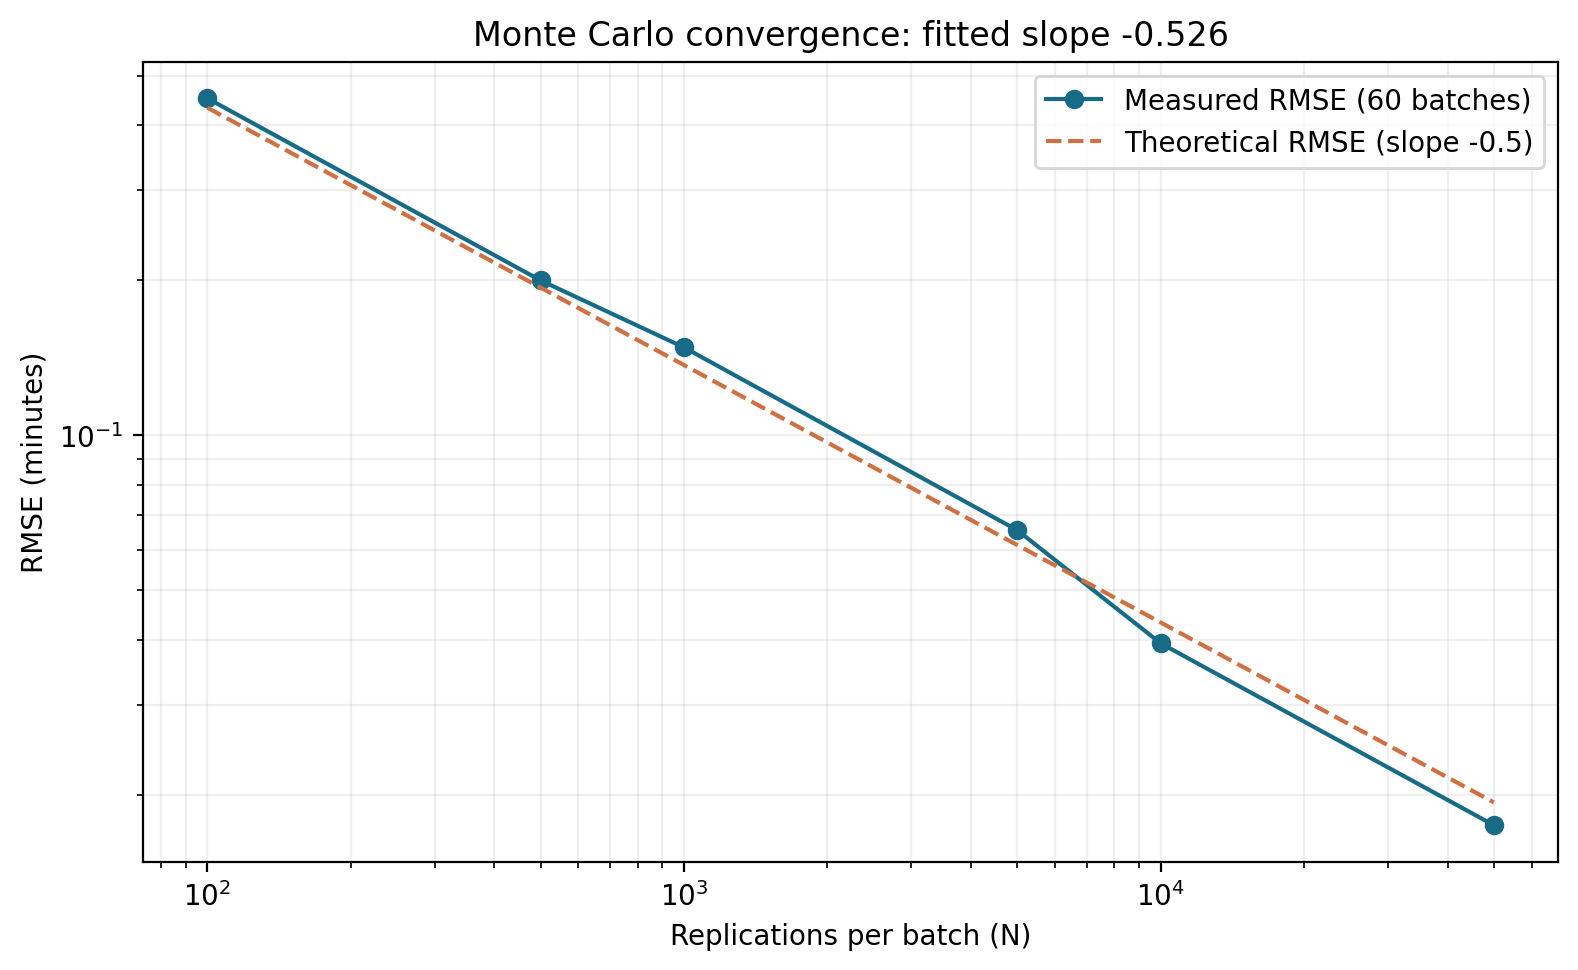

In [12]:
import numpy as np
import matplotlib.pyplot as plt

sample_sizes = np.array([100, 500, 1000, 5000, 10000, 50000])
batch_count = 60
benchmark_schedule = [dict(train='first', start=0, duration=10, segment=('P','Q')),
                      dict(train='second', start=10, duration=10, segment=('P','Q'))]
estimates = np.empty((batch_count, len(sample_sizes)))
for j in range(batch_count):
    rng = Random(31000 + j)
    total_wait = 0.0
    previous_n = 0
    for k, n in enumerate(sample_sizes):
        for _ in range(previous_n, int(n)):
            delays = {'first': rng.expovariate(0.2), 'second': rng.expovariate(0.2)}
            total_wait += simulate(delays, benchmark_schedule)[1][2]
        estimates[j, k] = total_wait / n
        previous_n = int(n)

rmse = np.sqrt(np.mean((estimates - 2.5)**2, axis=0))
theory_rmse = np.sqrt(18.75 / sample_sizes)
slope, intercept = np.polyfit(np.log(sample_sizes), np.log(rmse), 1)
print('Replications | Observed RMSE (min) | Theoretical RMSE (min)')
for n, observed, theoretical in zip(sample_sizes, rmse, theory_rmse):
    print(f'{n:12} | {observed:19.5f} | {theoretical:22.5f}')
print(f'Fitted slope: {slope:.3f}; theoretical slope: -0.500')
assert -0.65 <= slope <= -0.35, 'Observed slope outside predeclared tolerance'
print('PASS: observed convergence slope within 0.15 of -0.5.')

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(sample_sizes, rmse, 'o-', color='#176B87', label='Measured RMSE (60 batches)')
ax.loglog(sample_sizes, theory_rmse, '--', color='#CF7042', label='Theoretical RMSE (slope -0.5)')
ax.set(xlabel='Replications per batch (N)', ylabel='RMSE (minutes)',
       title=f'Monte Carlo convergence: fitted slope {slope:.3f}')
ax.grid(True, which='both', alpha=0.2)
ax.legend()
fig.tight_layout()
figure_dir = Path('figures') if Path('data').is_dir() else (Path('../figures') if Path('../data').is_dir() else Path('figures'))
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'monte-carlo-convergence.png', dpi=200, bbox_inches='tight')
plt.show()